In [223]:
#partie 1:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#loading dataset
df=pd.read_csv(r'C:\Users\Pc\OneDrive\Desktop\python_projects\Titanic-Dataset.csv',sep=';')
print("nombre de column,nombre de ligne: ",df.shape)

nombre de column,nombre de ligne:  (891, 12)


In [224]:
# identify data types
print(df.dtypes)


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [225]:
#numeriques
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(num_cols)

['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


In [226]:
#catégorielles
cqt_cols=df.select_dtypes(include=['object']).columns.tolist()
print(cqt_cols)

['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


C:\Users\Pc\AppData\Local\Temp\ipykernel_12296\2219310309.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cqt_cols=df.select_dtypes(include=['object']).columns.tolist()


In [227]:
# 5 ligne premier
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [228]:
#valeurs manquants
v_manq=df.isnull().sum()
print(v_manq)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [229]:
# partie 2:
#Gestion des valeurs manquantes
p_v_m=df.isnull().mean()*100
print("pourcentage des valeurs manquants: ",p_v_m)

pourcentage des valeurs manquants:  PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64


In [230]:
# supprimer la colonne'cabin' car il depasse 40% de valeurs manquants
df.drop(columns=['Cabin'],inplace=True)

In [231]:
# remplacer les valeurs manquantes de variable'age'
age_mediane=df['Age'].median()
df['Age']=df['Age'].fillna(age_mediane)
#remplacer les valeurs manquantes de Embarked
embarked_mode=df['Embarked'].mode()[0]
df['Embarked']=df['Embarked'].fillna(embarked_mode)
# verifier qu'il ne reste plus de valeurs manquantes
print("valeurs manquantes reste : ", df.isnull().sum())

valeurs manquantes reste :  PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


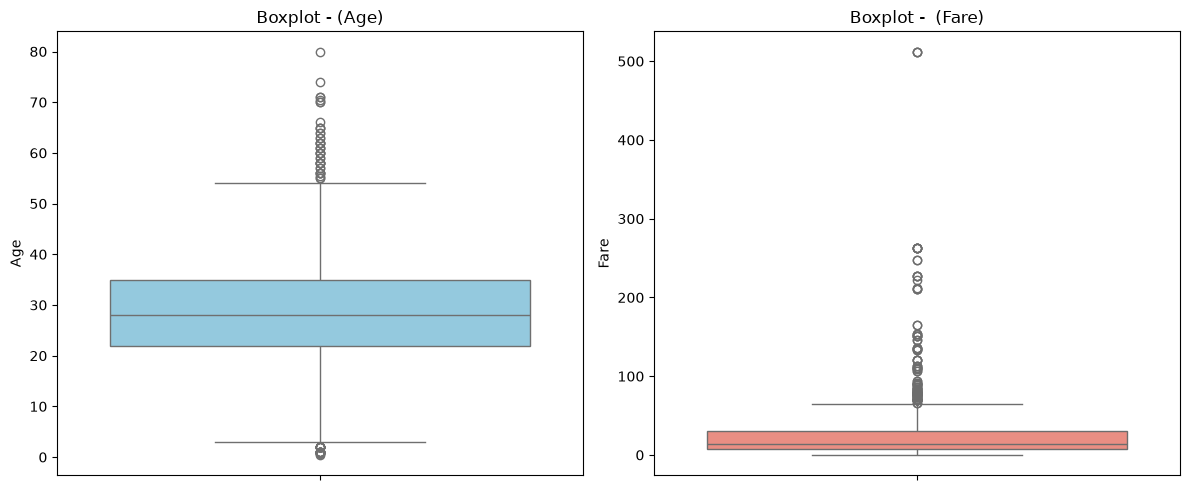

In [232]:
#Gestion des valeurs aberrantes :
#détecter des valeurs aberrantes
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['Age'], color='skyblue')
plt.title('Boxplot - (Age)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Fare'], color='salmon')
plt.title('Boxplot -  (Fare)')

plt.tight_layout()
plt.show()

In [233]:
# traitement des valeurs aberrantes:
# Remplacement des valeurs aberrantes par la médiane 
# Fonction pour traiter les valeurs aberrantes en les remplaçant par la médiane[span_4](start_span)[span_4](end_span)
def remplacer_valeurs_aberrantes_par_mediane(data, colonne):
    Q1 = data[colonne].quantile(0.25)
    Q3 = data[colonne].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferieure = Q1 - 1.5 * IQR
    limite_superieure = Q3 + 1.5 * IQR
    
    valeur_mediane = data[colonne].median()
    # Remplacer les valeurs aberrantes par la médiane
    data[colonne] = np.where((data[colonne] < limite_inferieure) | (data[colonne] > limite_superieure), valeur_mediane, data[colonne])

# Appliquer la fonction sur les colonnes 'Age' et 'Fare'
remplacer_valeurs_aberrantes_par_mediane(df, 'Age')
remplacer_valeurs_aberrantes_par_mediane(df, 'Fare')
    



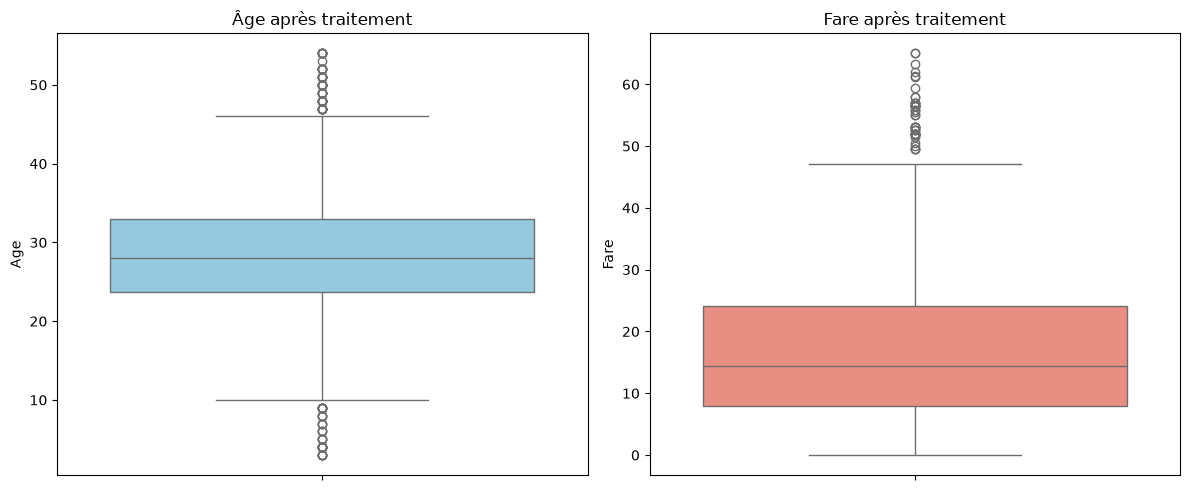

In [234]:
#verification apres le traitement
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['Age'], color='skyblue')
plt.title('Âge après traitement')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Fare'], color='salmon')
plt.title('Fare après traitement')

plt.tight_layout()
plt.show()

In [235]:
#separation Train\Test
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Survived', 'Name', 'Ticket'])
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (712, 8)
X_test: (179, 8)


In [236]:
# partie 3:
#encodage des variables catégorielles 
from sklearn.preprocessing import OneHotEncoder
# les colonnes avec des données catégorielles
cat_cols = ['Sex', 'Embarked']



In [ ]:
# OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_train_arr = encoder.fit_transform(X_train[cat_cols])
encoded_test_arr = encoder.transform(X_test[cat_cols])
encoded_col_names = encoder.get_feature_names_out(cat_cols)

# transfer les resultat au dataframe
X_train_cat = pd.DataFrame(encoded_train_arr, columns=encoded_col_names, index=X_train.index)
X_test_cat = pd.DataFrame(encoded_test_arr, columns=encoded_col_names, index=X_test.index)
print(X_train_cat.head(2))

     Sex_female  Sex_male  Embarked_C  Embarked_Q  Embarked_S
692         0.0       1.0         0.0         0.0         1.0
481         0.0       1.0         0.0         0.0         1.0


In [238]:
#normalisation et standardisation des données
#Normalisation (Min-Max scaling)
from sklearn.preprocessing import MinMaxScaler

num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

min_max_scaler = MinMaxScaler()
X_train_minmax_arr = min_max_scaler.fit_transform(X_train[num_cols])
X_test_minmax_arr = min_max_scaler.transform(X_test[num_cols])

X_train_minmax = pd.DataFrame(X_train_minmax_arr, columns=num_cols, index=X_train.index)
X_test_minmax = pd.DataFrame(X_test_minmax_arr, columns=num_cols, index=X_test.index)
print(X_train_minmax.head(2))


     Pclass       Age  SibSp  Parch      Fare
692     1.0  0.490196    0.0    0.0  0.869166
481     0.5  0.490196    0.0    0.0  0.000000


In [239]:
#Standardisation (Z-score)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled_arr = scaler.fit_transform(X_train[num_cols])
X_test_scaled_arr = scaler.transform(X_test[num_cols])

#transfer les resultat au dataframe
X_train_num = pd.DataFrame(X_train_scaled_arr, columns=num_cols, index=X_train.index)
X_test_num = pd.DataFrame(X_test_scaled_arr, columns=num_cols, index=X_test.index)

print(X_train_num.head(2))

       Pclass       Age     SibSp     Parch      Fare
692  0.829568 -0.067544 -0.465084 -0.466183  3.027097
481 -0.370945 -0.067544 -0.465084 -0.466183 -1.348827


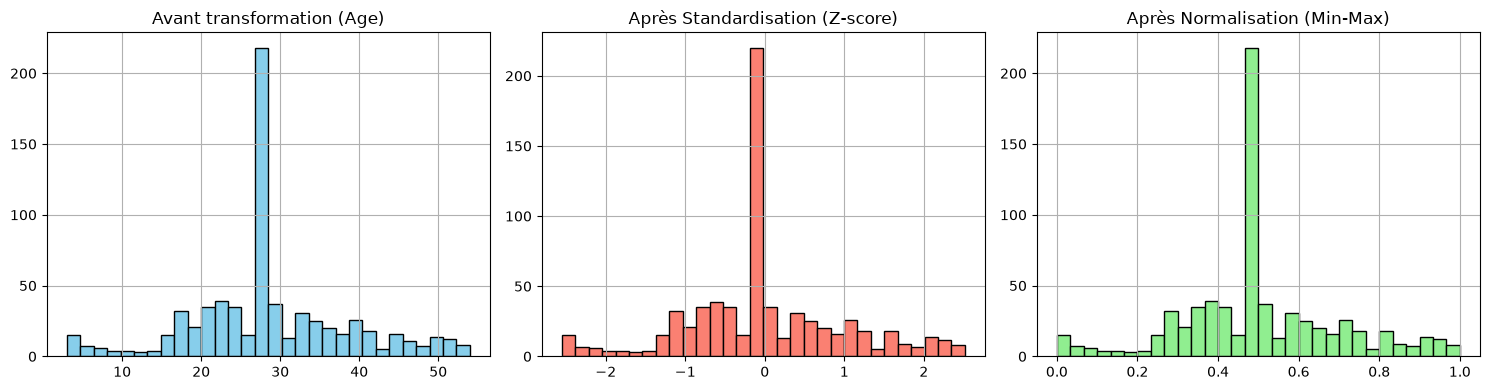

In [ ]:
#histogrammes
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
X_train['Age'].hist(bins=30, color='skyblue', edgecolor='black')
plt.title("Avant transformation (Age)")
plt.subplot(1, 3, 2)
X_train_num['Age'].hist(bins=30, color='salmon', edgecolor='black')
plt.title("Après Standardisation (Z-score)")
#  apres Normalisation (Min-Max)
plt.subplot(1, 3, 3)
X_train_minmax['Age'].hist(bins=30, color='lightgreen', edgecolor='black')
plt.title("Après Normalisation (Min-Max)")

plt.tight_layout()
plt.show()

In [241]:
# (Standardisation)&(One-Hot) 
X_train_final = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_final = pd.concat([X_test_num, X_test_cat], axis=1)


print("X_train_final:", X_train_final.shape)
print(" X_test_final:", X_test_final.shape)

X_train_final: (712, 10)
 X_test_final: (179, 10)


In [242]:
#partie 4:
#Identification du déséquilibre des classes :
print( "Identification du déséquilibre des classes ",y_train.value_counts())
print("\nPourcentages des classes (%) :",y_train.value_counts(normalize=True) * 100)

Identification du déséquilibre des classes  Survived
0    439
1    273
Name: count, dtype: int64

Pourcentages des classes (%) : Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


In [243]:
# Gestion du déséquilibre :
# Sous-échantillonnage (undersampling)
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = rus.fit_resample(X_train_final, y_train)

print("Après Sous-échantillonnage (Undersampling): ",y_train_under.value_counts())

Après Sous-échantillonnage (Undersampling):  Survived
0    273
1    273
Name: count, dtype: int64


In [244]:
# Sur-échantillonnage (oversampling)
from imblearn.over_sampling import SMOTE

# SMOTE
smote = SMOTE(random_state=42)

X_train_over, y_train_over = smote.fit_resample(X_train_final, y_train)

print(("Après Sur-échantillonnage (SMOTE) : "),y_train_over.value_counts())


Après Sur-échantillonnage (SMOTE) :  Survived
1    439
0    439
Name: count, dtype: int64
